# Exploratory Data Analysis
UCI Student Performance dataset (Maths 395 + Portuguese 649 records). Run this notebook from the `notebooks/` folder or the project root.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from src.data_loader import load_raw_data, validate_data
from src.data_preprocessing import engineer_features, student_fingerprint
sns.set_theme(style='whitegrid')

## 1. Loading and validation

In [2]:
raw = load_raw_data()
rep = validate_data(raw)
print('records:', rep['total_records'], '| missing:', rep['total_missing'], '| duplicates:', rep['duplicate_rows'])
print('grades within 0-20:', rep['grade_ranges_valid'], '| PII-like columns:', rep['pii_like_columns'])
raw.head(3)

records: 1044 | missing: 0 | duplicates: 0
grades within 0-20: True | PII-like columns: []


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,subject
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,6,5,6,6,Mathematics
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,4,5,5,6,Mathematics
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,10,7,8,10,Mathematics


## 2. Records are not distinct students
The dataset has no student id; students enrolled in both courses appear twice.

In [3]:
df = engineer_features(raw)
df['student_group'] = student_fingerprint(df)
print('records:', len(df), '| distinct student fingerprints:', df['student_group'].nunique())

records: 1044 | distinct student fingerprints: 662


## 3. Absences and the final grade
Every record with G3 = 0 has 0 absences, which distorts the relationship.

In [4]:
z = df[df.G3 == 0]
print('G3 == 0 records:', len(z), '| of which absences == 0:', (z.absences == 0).sum())
print('corr(absences, G3) all rows:', round(df.absences.corr(df.G3), 3))
nz = df[df.G3 > 0]
print('corr(absences, G3) excluding G3 == 0:', round(nz.absences.corr(nz.G3), 3))

G3 == 0 records: 53 | of which absences == 0: 53
corr(absences, G3) all rows: -0.046
corr(absences, G3) excluding G3 == 0: -0.218


## 4. Correlations

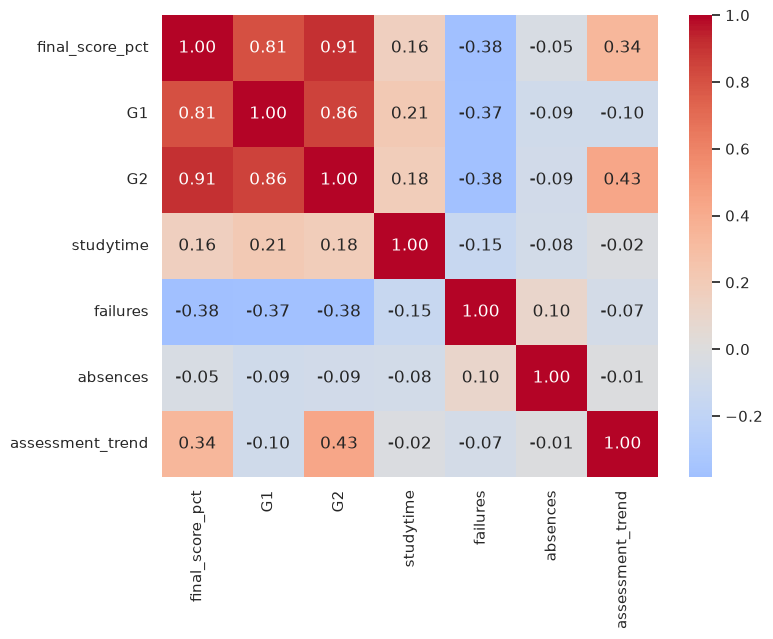

In [5]:
cols = ['final_score_pct','G1','G2','studytime','failures','absences','assessment_trend']
plt.figure(figsize=(8,6)); sns.heatmap(df[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0); plt.show()

## 5. How much does G2 explain?
A rule that predicts final = G2 needs no model.

In [6]:
from sklearn.metrics import mean_absolute_error, r2_score
print('MAE of final = G2 (score points):', round(mean_absolute_error(df.final_score_pct, df.G2*5), 2))
print('R2  of final = G2:', round(r2_score(df.final_score_pct, df.G2*5), 3))

MAE of final = G2 (score points): 4.2
R2  of final = G2: 0.825
